## Business Question:

**Which Customer segment will give the highest ROI on retention campaign, and how should the marketing team allocate budget?**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

## 1. Data Collection and Inspection:

In [2]:
# loading the dataset:

df= pd.read_csv("../data/online_retail_II.csv", encoding= 'unicode_escape')
df

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom
...,...,...,...,...,...,...,...,...
1067366,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
1067367,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
1067368,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
1067369,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France


In [3]:
# Checking the information of the dataset:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Invoice      1067371 non-null  str    
 1   StockCode    1067371 non-null  str    
 2   Description  1062989 non-null  str    
 3   Quantity     1067371 non-null  int64  
 4   InvoiceDate  1067371 non-null  str    
 5   Price        1067371 non-null  float64
 6   Customer ID  824364 non-null   float64
 7   Country      1067371 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 65.1 MB


In [4]:
# Summary statistics of the dataset:
df.describe()

,Quantity,Price,Customer ID
count,1.067371e+06,1.067371e+06,824364.000000
mean,9.938898e+00,4.649388e+00,15324.638504
std,1.727058e+02,1.235531e+02,1697.464450
min,-8.099500e+04,-5.359436e+04,12346.000000
25%,1.000000e+00,1.250000e+00,13975.000000
50%,3.000000e+00,2.100000e+00,15255.000000
75%,1.000000e+01,4.150000e+00,16797.000000
max,8.099500e+04,3.897000e+04,18287.000000


In [5]:
# Checking for missing values in the dataset:
df.isnull().sum()

Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

In [6]:
# Duplicate values in the dataset:
df.duplicated().sum()

np.int64(34335)

In [7]:
# Checking how much unique customers are there in the dataset:

df['Customer ID'].nunique()

5942

In [8]:
# Number of unique invoices in the dataset:

df['Invoice'].nunique()

53628

In [9]:
# Seeing the Unique values of the categorical columns:

for col in df.columns:
    if df[col].dtype == 'str':
        print(f"Column: {col}")
        print(df[col].value_counts())
        print("\n")

Column: Invoice
Invoice
537434     1350
538071     1304
537638     1202
537237     1194
536876     1186
           ... 
581487        1
581491        1
C581499       1
581566        1
C581568       1
Name: count, Length: 53628, dtype: int64


Column: StockCode
StockCode
85123A    5829
22423     4424
85099B    4216
21212     3318
20725     3259
          ... 
85049c       1
84971l       1
85034b       1
23609        1
23617        1
Name: count, Length: 5305, dtype: int64


Column: Description
Description
WHITE HANGING HEART T-LIGHT HOLDER    5918
REGENCY CAKESTAND 3 TIER              4412
JUMBO BAG RED RETROSPOT               3469
ASSORTED COLOUR BIRD ORNAMENT         2958
PARTY BUNTING                         2765
                                      ... 
wet?                                     1
lost??                                   1
???                                      1
wet boxes                                1
????damages????                          1
Name: count, Leng

In [10]:
# Analyzing negative quantity values and which invoices are associated with them:

neg = df[df['Quantity'] < 0]
print(len(neg))
print(neg['Invoice'].astype(str).str.startswith('C').value_counts())
print(neg['Customer ID'].isna().mean())   # share with no customer
print((neg['Price'] == 0).mean())

22950
Invoice
True     19493
False     3457
Name: count, dtype: int64
0.18326797385620916
0.1506318082788671


**Findings on negative quantities:**

- 19,493 rows (85%) are cancellations (`C` invoices). These are real returns against earlier sales.
- 3,457 rows (15%) are not `C` invoices. This matches the share of rows with `Price == 0` (15.06%), so they are almost certainly stock adjustments and write-offs (damaged or lost goods, "adjust" entries), not customer behaviour.
- 18.3% of the negative rows (about 4,200) have no Customer ID. That is more than the 3,457 adjustments, so some cancellations also lack a customer. They cannot be attributed to anyone in RFM either way.

## 2. Handling Missing Values:

In [11]:
df.isnull().sum()

Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

In [12]:
df.dropna(inplace= True)

In [13]:
df.isnull().sum()

Invoice        0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
Price          0
Customer ID    0
Country        0
dtype: int64

In [14]:
df.shape

(824364, 8)

In [15]:
df

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom
...,...,...,...,...,...,...,...,...
1067366,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
1067367,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
1067368,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
1067369,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France


## 3. Fixing Inconsistent Formatting:

In [16]:
df['StockCode'] = df['StockCode'].astype(str).str.strip().str.upper()
df['StockCode']

0           85048
1          79323P
2          79323W
3           22041
4           21232
            ...  
1067366     22899
1067367     23254
1067368     23255
1067369     22138
1067370      POST
Name: StockCode, Length: 824364, dtype: str

In [17]:
df['Description'] = df['Description'].str.strip()
df['Description']

0          15CM CHRISTMAS GLASS BALL 20 LIGHTS
1                           PINK CHERRY LIGHTS
2                          WHITE CHERRY LIGHTS
3                  RECORD FRAME 7" SINGLE SIZE
4               STRAWBERRY CERAMIC TRINKET BOX
                          ...                 
1067366            CHILDREN'S APRON DOLLY GIRL
1067367           CHILDRENS CUTLERY DOLLY GIRL
1067368        CHILDRENS CUTLERY CIRCUS PARADE
1067369           BAKING SET 9 PIECE RETROSPOT
1067370                                POSTAGE
Name: Description, Length: 824364, dtype: str

## 4. Handling Duplicates:

In [18]:
df.duplicated().sum()

np.int64(26479)

In [19]:
df[df.duplicated(keep=False)]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
367,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329.0,United Kingdom
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom
...,...,...,...,...,...,...,...,...
1067136,581538,22068,BLACK PIRATE TREASURE CHEST,1,2011-12-09 11:34:00,0.39,14446.0,United Kingdom
1067150,581538,23318,BOX OF 6 MINI VINTAGE CRACKERS,1,2011-12-09 11:34:00,2.49,14446.0,United Kingdom
1067153,581538,22992,REVOLVER WOODEN RULER,1,2011-12-09 11:34:00,1.95,14446.0,United Kingdom
1067160,581538,22694,WICKER STAR,1,2011-12-09 11:34:00,2.10,14446.0,United Kingdom


In [20]:
df[df.duplicated(keep=False)].sort_values(list(df.columns))

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
391,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
386,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
...,...,...,...,...,...,...,...,...
965610,C574510,22360,GLASS JAR ENGLISH CONFECTIONERY,-1,2011-11-04 13:25:00,2.95,15110.0,United Kingdom
986868,C575940,23309,SET OF 60 I LOVE LONDON CAKE CASES,-24,2011-11-13 11:38:00,0.55,17838.0,United Kingdom
986869,C575940,23309,SET OF 60 I LOVE LONDON CAKE CASES,-24,2011-11-13 11:38:00,0.55,17838.0,United Kingdom
1055441,C580764,22667,RECIPE BOX RETROSPOT,-12,2011-12-06 10:38:00,2.95,14562.0,United Kingdom


In [21]:
cols = ['Invoice', 'StockCode', 'Customer ID']

df.duplicated(subset=cols).sum()
df[df.duplicated(subset=cols, keep=False)].sort_values(cols)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
289,489488,22125,UNION JACK HOT WATER BOTTLE,2,2009-12-01 10:59:00,5.95,17238.0,United Kingdom
299,489488,22125,UNION JACK HOT WATER BOTTLE,1,2009-12-01 10:59:00,5.95,17238.0,United Kingdom
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
391,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
373,489517,21790,VINTAGE SNAP CARDS,4,2009-12-01 11:34:00,0.85,16329.0,United Kingdom
...,...,...,...,...,...,...,...,...
1045595,C580263,M,Manual,-16,2011-12-02 12:43:00,0.29,12536.0,France
1055441,C580764,22667,RECIPE BOX RETROSPOT,-12,2011-12-06 10:38:00,2.95,14562.0,United Kingdom
1055442,C580764,22667,RECIPE BOX RETROSPOT,-12,2011-12-06 10:38:00,2.95,14562.0,United Kingdom
1057260,C580968,23534,WALL ART STOP FOR TEA,-4,2011-12-06 14:57:00,5.95,15622.0,United Kingdom


In [22]:
df[df.duplicated(subset=cols, keep=False)].groupby(cols).size().sort_values(ascending=False)


Invoice  StockCode  Customer ID
555524   22698      16923.0        20
         22697      16923.0        12
537646   22585      17591.0        10
537224   70007      13174.0        10
536412   21448      17920.0        10
                                   ..
495016   21733      14649.0         2
C578073  M          18139.0         2
C580263  M          12536.0         2
C580764  22667      14562.0         2
489517   21791      16329.0         2
Length: 33995, dtype: int64

In [23]:
df.duplicated().mean() * 100

np.float64(3.212051957630367)

In [24]:
df = df.drop_duplicates()
df

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom
...,...,...,...,...,...,...,...,...
1067366,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
1067367,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
1067368,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
1067369,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France


In [25]:
df.duplicated().sum()

np.int64(0)

In [26]:
df

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom
...,...,...,...,...,...,...,...,...
1067366,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
1067367,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
1067368,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
1067369,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France


## 5. Correcting Data Types:

In [27]:
df.dtypes

Invoice            str
StockCode          str
Description        str
Quantity         int64
InvoiceDate        str
Price          float64
Customer ID    float64
Country            str
dtype: object

In [28]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

In [29]:
df['Customer ID'] = df['Customer ID'].astype(int)

In [30]:
df.dtypes

Invoice                   str
StockCode                 str
Description               str
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID             int64
Country                   str
dtype: object

## 6. Outlier Handling:

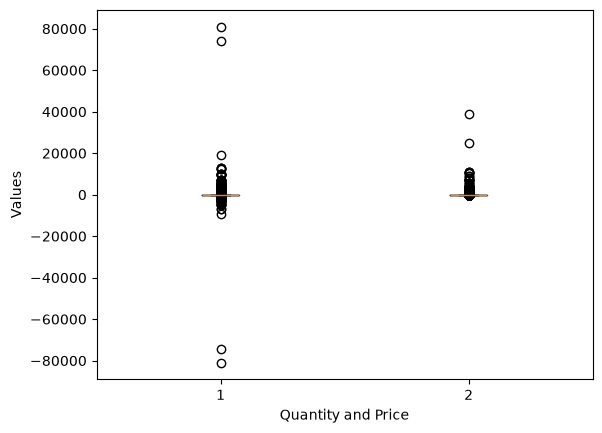

In [31]:
plt.boxplot(df[['Quantity', 'Price']])
plt.xlabel('Quantity and Price')
plt.ylabel('Values')
plt.show()

In [32]:
# Flagging the cancellations and invalid transactions:
df = df.reset_index(drop=True)

df['Is_Cancellation'] = df['Invoice'].str.startswith('C')
df['Is_Invalid'] = (df['Quantity'] <= 0) | (df['Price'] <= 0)
df['TotalPrice'] = df['Quantity'] * df['Price']

print(len(df))
print(df[['Is_Cancellation', 'Is_Invalid']].sum())

797885
Is_Cancellation    18390
Is_Invalid         18460
dtype: int64


In [33]:
# seeing how many invalid transactions but not cancelled are there in the dataset:
odd = df[df['Is_Invalid'] & ~df['Is_Cancellation']]
print(len(odd))
odd['Description'].value_counts().head(10)
odd[['Quantity', 'Price']].describe()

70


,Quantity,Price
count,70.000000,70.0
mean,210.757143,0.0
std,1497.681768,0.0
min,1.000000,0.0
25%,1.000000,0.0
50%,5.000000,0.0
75%,12.000000,0.0
max,12540.000000,0.0


In [34]:
valid = df[~df['Is_Invalid']]

valid.nlargest(10, 'TotalPrice')[['Invoice', 'StockCode', 'Description', 'Quantity', 'Price', 'Customer ID']]

,Invoice,StockCode,Description,Quantity,Price,Customer ID
797411,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,16446
433791,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,12346
553676,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,649.50,15098
341726,530715,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,9360,1.69,15838
99582,502263,M,Manual,1,10953.50,12918
280603,524159,M,Manual,1,10468.80,14063
51409,496115,M,Manual,1,8985.60,17949
174581,511465,15044A,PINK PAPER PARASOL,3500,2.55,18008
516187,551697,POST,POSTAGE,1,8142.75,16029
648280,567423,23243,SET OF TEA COFFEE SUGAR TINS PANTRY,1412,5.06,17450


In [35]:
df[df['Quantity'].abs() == 80995]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Is_Cancellation,Is_Invalid,TotalPrice
797411,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446,United Kingdom,False,False,168469.6
797412,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,16446,United Kingdom,True,True,-168469.6


## 7. Removing Reversed Orders

Large purchases that were fully cancelled later (an order plus its matching `C` invoice) are removed, because they would inflate a customer's Monetary value.

In [36]:
# Drop the order and its cancellation:
df = df[~df['Invoice'].isin(['581483', 'C581484'])]

In [37]:
canc = df[df['Is_Cancellation']].copy()
canc['Quantity'] = canc['Quantity'].abs()

buys = df[~df['Is_Cancellation'] & ~df['Is_Invalid']]# seeing how many valid transactions and not cancelled are there in the dataset.
matched = buys.merge(canc[['Customer ID', 'StockCode', 'Quantity']],
                    on=['Customer ID', 'StockCode', 'Quantity']) # matched transactions are those which have a valid purchase and a corresponding cancellation for the same customer, stock code, and quantity.
print(len(matched))
matched.nlargest(10, 'TotalPrice')[['Invoice', 'Description', 'Quantity', 'Price', 'Customer ID', 'TotalPrice']]

15177


,Invoice,Description,Quantity,Price,Customer ID,TotalPrice
8862,541431,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,12346,77183.6
11418,556444,PICNIC BASKET WICKER 60 PIECES,60,649.50,15098,38970.0
7194,530715,ROTATING SILVER ANGELS T-LIGHT HLDR,9360,1.69,15838,15818.4
2131,502263,Manual,1,10953.50,12918,10953.5
2132,502263,Manual,1,10953.50,12918,10953.5
6072,524159,Manual,1,10468.80,14063,10468.8
6073,524159,Manual,1,10468.80,14063,10468.8
6074,524159,Manual,1,10468.80,14063,10468.8
6075,524159,Manual,1,10468.80,14063,10468.8
1144,496115,Manual,1,8985.60,17949,8985.6


In [38]:
# Viewing cancellation details for specific customers:

for cid in [12346, 15098, 15838]:
    print(cid)
    print(df[(df['Customer ID'] == cid) & df['Is_Cancellation']]
            [['Invoice', 'StockCode', 'Description', 'Quantity', 'Price', 'InvoiceDate']])

12346
        Invoice StockCode                          Description  Quantity  \
49055   C495800    ADJUST  Adjustment by john on 26/01/2010 17        -1   
196542  C514024         M                               Manual        -1   
196543  C514024         M                               Manual        -1   
196544  C514024         M                               Manual        -1   
196545  C514024         M                               Manual        -1   
196546  C514024         M                               Manual        -3   
196547  C514024         M                               Manual        -1   
196548  C514024         M                               Manual        -4   
196549  C514024         M                               Manual        -1   
196550  C514024         M                               Manual        -1   
290224  C525099         D                             Discount        -1   
291616  C525274   TEST001              This is a test product.        -1   
433796

In [39]:
# Viewing details for a specific customer and stock code:
print(df[(df['Customer ID'] == 15838) & (df['StockCode'] == '84347')]
        [['Invoice', 'Quantity', 'Price', 'InvoiceDate', 'TotalPrice']])

        Invoice  Quantity  Price         InvoiceDate  TotalPrice
253960   521315      1920   1.66 2010-09-03 12:01:00      3187.2
298398   525968      3120   1.66 2010-10-08 10:10:00      5179.2
341726   530715      9360   1.69 2010-11-04 11:36:00     15818.4
399321  C536757     -9360   0.03 2010-12-02 14:23:00      -280.8


In [40]:
# Removing specific invoices from the dataset:
df = df[~df['Invoice'].isin(['541431', 'C541433', '556444', 'C556445', '530715', 'C536757'])]

## 8. Building the RFM Base

The base keeps valid purchases only: no cancellations, invalid rows or non-product stock codes (postage, manual entries, fees, tests).

In [41]:
df = df.reset_index(drop=True)
df['Is_Cancellation'] = df['Invoice'].str.startswith('C')
df['Is_Invalid'] = (df['Quantity'] <= 0) | (df['Price'] <= 0)
df['Is_NonProduct'] = ~df['StockCode'].str.match(r'^\d{5}')
df['TotalPrice'] = df['Quantity'] * df['Price']

print(df[df['Is_NonProduct']]['StockCode'].value_counts())
rfm_base = df[~df['Is_Cancellation'] & ~df['Is_Invalid'] & ~df['Is_NonProduct']]
print(len(rfm_base))
rfm_base.nlargest(10, 'TotalPrice')[['Invoice','Description','Quantity','Price','Customer ID','TotalPrice']]

StockCode
POST            1983
M               1084
C2               254
D                170
ADJUST            61
BANK CHARGES      37
PADS              19
DOT               16
CRUK              16
TEST001           15
ADJUST2            3
SP1002             2
TEST002            1
Name: count, dtype: int64
776572


,Invoice,Description,Quantity,Price,Customer ID,TotalPrice
174581,511465,PINK PAPER PARASOL,3500,2.55,18008,8925.00
648273,567423,SET OF TEA COFFEE SUGAR TINS PANTRY,1412,5.06,17450,7144.72
429386,540815,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,15749,6539.40
507289,550461,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,15749,6539.40
298398,525968,ROTATING SILVER ANGELS T-LIGHT HLDR,3120,1.66,15838,5179.20
708306,573003,RABBIT NIGHT LIGHT,2400,2.08,14646,4992.00
429384,540815,WHITE HANGING HEART T-LIGHT HOLDER,1930,2.55,15749,4921.50
507285,550461,WHITE HANGING HEART T-LIGHT HOLDER,1930,2.40,15749,4632.00
429446,540818,DOORMAT FAIRY CAKE,670,6.75,15749,4522.50
280778,524181,VINTAGE UNION JACK CUSHION COVER,648,6.89,17450,4464.72


## 9. RFM Table and Scoring

In [42]:
snapshot = rfm_base['InvoiceDate'].max() + pd.Timedelta(days=1)

# Calculating RFM metrics for each customer:
rfm = (rfm_base.groupby('Customer ID')
     .agg(Recency=('InvoiceDate', lambda x: (snapshot - x.max()).days),
          Frequency=('Invoice', 'nunique'),
          Monetary=('TotalPrice', 'sum'))
     .reset_index())

print(len(rfm))
rfm.describe()

5852


,Customer ID,Recency,Frequency,Monetary
count,5852.000000,5852.000000,5852.000000,5852.000000
mean,15319.707109,200.267772,6.252563,2865.161061
std,1714.929942,208.531131,12.749085,14087.653735
min,12346.000000,1.000000,1.000000,2.900000
25%,13837.750000,25.750000,1.000000,339.242500
50%,15320.500000,95.000000,3.000000,855.580000
75%,16802.250000,379.000000,7.000000,2236.857500
max,18287.000000,739.000000,373.000000,580987.040000


In [43]:
rfm['R_Score'] = pd.qcut(rfm['Recency'], 5, labels=[5,4,3,2,1]) # The recency score is inversely related to the recency value, so we assign higher scores to lower recency values.
# F_Score is assigned with fixed bins in the cells below: qcut on Frequency (even with rank) gives different scores to customers with the same number of orders.
rfm['M_Score'] = pd.qcut(rfm['Monetary'], 5, labels=[1,2,3,4,5]) # The monetary score is directly related to the monetary value, so we assign higher scores to higher monetary values.

In [44]:
rfm

,Customer ID,Recency,Frequency,Monetary,R_Score,M_Score
0,12346,529,2,169.36,1,1
1,12347,2,8,4921.53,5,5
2,12348,75,5,1658.40,3,4
3,12349,19,3,3678.69,5,5
4,12350,310,1,294.40,2,2
...,...,...,...,...,...,...
5847,18283,4,22,2658.95,5,4
5848,18284,432,1,411.68,1,2
5849,18285,661,1,377.00,1,2
5850,18286,477,2,1246.43,1,4


In [45]:
# Viewing the distribution of the Frequency metric:
rfm['Frequency'].value_counts().sort_index().head(10)
rfm['Frequency'].quantile([.2, .4, .6, .8])

0.2    1.0
0.4    2.0
0.6    4.0
0.8    8.0
Name: Frequency, dtype: float64

In [46]:
# Creating RFM scores based on specific bins for Recency, Frequency, and Monetary values:
rfm['F_Score'] = pd.cut(rfm['Frequency'],
                        bins=[0, 1, 2, 4, 8, float('inf')],
                        labels=[1, 2, 3, 4, 5]).astype(int)

## 10. Customer Segmentation

In [47]:
# Calculating the overall RFM score by summing the individual R, F, and M scores:
rfm['RFM_Score'] = rfm['R_Score'].astype(int) + rfm['F_Score'] + rfm['M_Score'].astype(int)

# Defining a function to segment customers based on their RFM scores:
def segment(r):
    R, F = int(r['R_Score']), int(r['F_Score'])
    if R >= 4 and F >= 4: return 'Champions'
    if R >= 3 and F >= 3: return 'Loyal'
    if R >= 4 and F <= 2: return 'New / Promising'
    if R <= 2 and F >= 3: return 'At Risk'
    if R <= 2 and F <= 2: return 'Lost / Hibernating'
    return 'Needs Attention'

rfm['Segment'] = rfm.apply(segment, axis=1)

rfm.groupby('Segment').agg(Customers=('Customer ID', 'count'),
                        AvgMonetary=('Monetary', 'mean'),
                        TotalMonetary=('Monetary', 'sum')).sort_values('TotalMonetary', ascending=False)

,Customers,AvgMonetary,TotalMonetary
Segment,,,
Champions,1402,8355.320221,11714158.95
Loyal,1178,2047.393667,2411829.74
At Risk,707,2044.198769,1445248.53
Lost / Hibernating,1630,423.819497,690825.78
New / Promising,514,543.317646,279265.27
Needs Attention,421,535.853349,225594.26


In [48]:
rfm.groupby('Segment')['Monetary'].agg(['mean', 'median', 'max'])

,mean,median,max
Segment,,,
At Risk,2044.198769,1143.270,65500.07
Champions,8355.320221,3549.530,580987.04
Lost / Hibernating,423.819497,292.340,11880.84
Loyal,2047.393667,1260.145,26278.86
Needs Attention,535.853349,375.100,5416.32
New / Promising,543.317646,381.050,17437.66


## 11. Retention Campaign ROI Model

All margin, cost and response inputs are placeholders.

In [49]:
# Calculating the annual value for each customer based on their monetary value and the time span of the dataset:
years = (rfm_base['InvoiceDate'].max() - rfm_base['InvoiceDate'].min()).days / 365
rfm['AnnualValue'] = rfm['Monetary'] / years

# Gross margin assumption:
margin = 0.30   # PLACEHOLDER: gross margin

# Defining assumptions for cost per customer and incremental response rate for each customer segment:
assump = pd.DataFrame({
    'CostPerCustomer': [3.0, 3.0, 3.0, 3.0, 3.0, 3.0],          # PLACEHOLDER
    'IncrementalResponse': [0.02, 0.05, 0.12, 0.02, 0.08, 0.05]  # PLACEHOLDER (Champions set low: they already buy often)
}, index=['Champions', 'Loyal', 'At Risk', 'Lost / Hibernating',
        'New / Promising', 'Needs Attention'])

# Calculating the expected profit and ROI for each customer segment based on the assumptions:
seg = (rfm.groupby('Segment')
        .agg(Customers=('Customer ID', 'count'),
            AvgAnnualValue=('AnnualValue', 'mean'))
        .join(assump))

# Calculating the cost, expected profit, and ROI for each segment:
seg['Cost'] = seg['Customers'] * seg['CostPerCustomer']
seg['ExpectedProfit'] = (seg['Customers'] * seg['IncrementalResponse']
                         * seg['AvgAnnualValue'] * margin)
seg['ROI'] = (seg['ExpectedProfit'] - seg['Cost']) / seg['Cost']

seg.sort_values('ROI', ascending=False)

,Customers,AvgAnnualValue,CostPerCustomer,IncrementalResponse,Cost,ExpectedProfit,ROI
Segment,,,,,,,
At Risk,707,1011.019717,3.0,0.12,2121.0,25732.473827,11.132237
Champions,1402,4132.373822,3.0,0.02,4206.0,34761.528591,7.264748
Loyal,1178,1012.599849,3.0,0.05,3534.0,17892.639331,4.062999
New / Promising,514,268.714012,3.0,0.08,1542.0,3314.856050,1.149712
Needs Attention,421,265.022320,3.0,0.05,1263.0,1673.615953,0.325112
Lost / Hibernating,1630,209.612624,3.0,0.02,4890.0,2050.011461,-0.580775


In [50]:
# Performing sensitivity analysis by varying the incremental response rate for the 'Champions' segment and calculating the corresponding ROI:
for champ_rate in [0.01, 0.02, 0.03, 0.05]:
    a = assump.copy(); a.loc['Champions', 'IncrementalResponse'] = champ_rate
    t = seg.drop(columns=['CostPerCustomer', 'IncrementalResponse']).join(a)
    roi = (t['Customers'] * t['IncrementalResponse'] * t['AvgAnnualValue'] * margin - t['Customers'] * t['CostPerCustomer']) / (t['Customers'] * t['CostPerCustomer'])
    print(champ_rate, roi.round(1).to_dict())

0.01 {'At Risk': 11.1, 'Champions': 3.1, 'Lost / Hibernating': -0.6, 'Loyal': 4.1, 'Needs Attention': 0.3, 'New / Promising': 1.1}
0.02 {'At Risk': 11.1, 'Champions': 7.3, 'Lost / Hibernating': -0.6, 'Loyal': 4.1, 'Needs Attention': 0.3, 'New / Promising': 1.1}
0.03 {'At Risk': 11.1, 'Champions': 11.4, 'Lost / Hibernating': -0.6, 'Loyal': 4.1, 'Needs Attention': 0.3, 'New / Promising': 1.1}
0.05 {'At Risk': 11.1, 'Champions': 19.7, 'Lost / Hibernating': -0.6, 'Loyal': 4.1, 'Needs Attention': 0.3, 'New / Promising': 1.1}


In [51]:
# Breakeven response rate: what Champions / Loyal would need to match the ROI of At Risk:
m, c = margin, 3.0
for s in ['Champions', 'Loyal']:
    v = seg.loc[s, 'AvgAnnualValue']
    target = seg.loc['At Risk', 'ROI']
    print(s, 'breakeven response:', round((target + 1) * c / (v * m), 4))

# Sensitivity on At Risk too (it is the segment the recommendation rests on)
for r in [0.03, 0.05, 0.08, 0.12]:
    v = seg.loc['At Risk', 'AvgAnnualValue']
    print('At Risk response', r, '-> ROI', round(r * v * m / c - 1, 1))

# Mean vs median, so a few wholesale accounts don't skew the averages
rfm.groupby('Segment')['AnnualValue'].agg(['mean', 'median'])

Champions breakeven response: 0.0294
Loyal breakeven response: 0.1198
At Risk response 0.03 -> ROI 2.0
At Risk response 0.05 -> ROI 4.1
At Risk response 0.08 -> ROI 7.1
At Risk response 0.12 -> ROI 11.1


,mean,median
Segment,,
At Risk,1011.019717,565.438415
Champions,4132.373822,1755.526355
Lost / Hibernating,209.612624,144.585501
Loyal,1012.599849,623.242446
Needs Attention,265.022320,185.516938
New / Promising,268.714012,188.459688


## 12. Budget Allocation

In [52]:
budget = 5000   # PLACEHOLDER total campaign budget
hurdle = 1.0    # minimum ROI worth funding (your call)

# Allocating the budget to the segments based on their ROI and the defined hurdle rate:
alloc = seg.sort_values('ROI', ascending=False).copy()
alloc = alloc[alloc['ROI'] > hurdle]

remaining, spend = budget, []
for s, row in alloc.iterrows():
    x = min(row['Cost'], remaining)   # cap at customers x cost per customer
    spend.append(x); remaining -= x
alloc['Spend'] = spend
alloc['ExpectedProfit'] = alloc['Spend'] * (1 + alloc['ROI']) - alloc['Spend']
alloc[['Customers', 'ROI', 'Spend', 'ExpectedProfit']]

,Customers,ROI,Spend,ExpectedProfit
Segment,,,,
At Risk,707,11.132237,2121.0,23611.473827
Champions,1402,7.264748,2879.0,20915.208468
Loyal,1178,4.062999,0.0,0.000000
New / Promising,514,1.149712,0.0,0.000000


In [53]:
assump.loc['Champions', 'IncrementalResponse'] = 0.02

seg = (rfm.groupby('Segment')
          .agg(Customers=('Customer ID', 'count'),
               AvgAnnualValue=('AnnualValue', 'mean'))
          .join(assump))
seg['Cost'] = seg['Customers'] * seg['CostPerCustomer']
seg['ROI'] = (seg['Customers'] * seg['IncrementalResponse'] * seg['AvgAnnualValue'] * margin - seg['Cost']) / seg['Cost']

alloc = seg.sort_values('ROI', ascending=False).copy()
alloc = alloc[alloc['ROI'] > hurdle]
remaining, spend = budget, []
for s, row in alloc.iterrows():
    x = min(row['Cost'], remaining)
    spend.append(x); remaining -= x
alloc['Spend'] = spend
alloc['NetProfit'] = alloc['Spend'] * alloc['ROI']
alloc[['Customers', 'ROI', 'Spend', 'NetProfit']]

,Customers,ROI,Spend,NetProfit
Segment,,,,
At Risk,707,11.132237,2121.0,23611.473827
Champions,1402,7.264748,2879.0,20915.208468
Loyal,1178,4.062999,0.0,0.000000
New / Promising,514,1.149712,0.0,0.000000


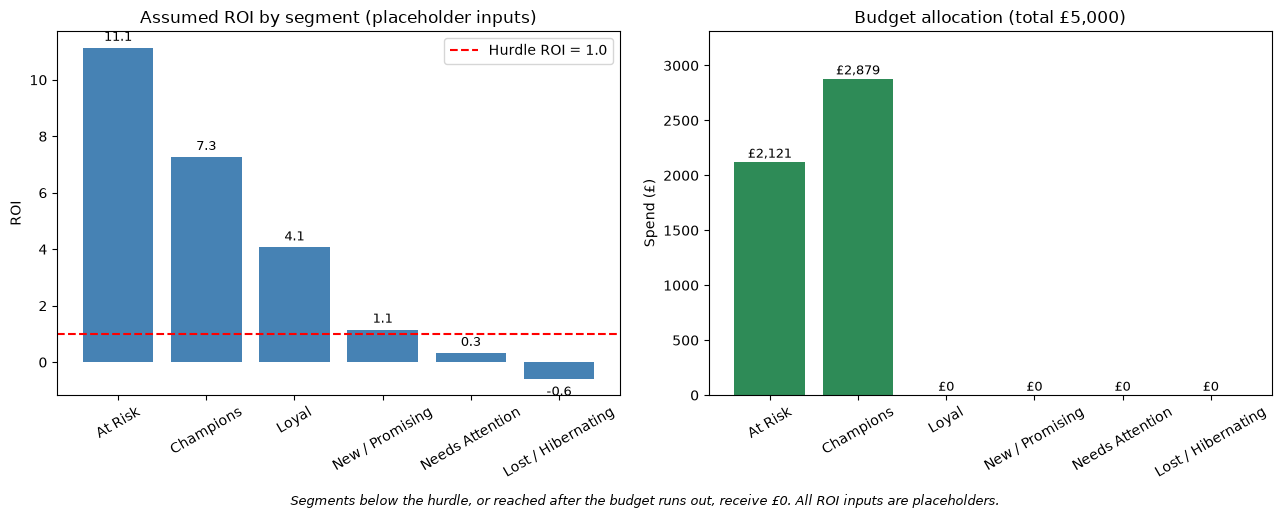

In [54]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# Left: ROI by segment
order = seg.sort_values('ROI', ascending=False)
bars = ax[0].bar(order.index, order['ROI'], color='steelblue')
ax[0].axhline(hurdle, color='red', linestyle='--', label=f'Hurdle ROI = {hurdle}')
ax[0].set_title('Assumed ROI by segment (placeholder inputs)')
ax[0].set_ylabel('ROI')
ax[0].tick_params(axis='x', rotation=30)
ax[0].legend()

for i, v in enumerate(order['ROI']):
    offset = 0.25 if v >= 0 else -0.6
    ax[0].text(i, v + offset, f'{v:.1f}', ha='center', fontsize=9)

# Right: spend for every segment, including those that get £0
full = alloc['Spend'].reindex(order.index, fill_value=0)
ax[1].bar(full.index, full.values, color='seagreen')
ax[1].set_title(f'Budget allocation (total £{budget:,})')
ax[1].set_ylabel('Spend (£)')
ax[1].tick_params(axis='x', rotation=30)

for i, v in enumerate(full.values):
    ax[1].text(i, v + 40, f'£{v:,.0f}', ha='center', fontsize=9)

ax[1].set_ylim(0, full.max() * 1.15)
fig.text(0.5, -0.02,
        'Segments below the hurdle, or reached after the budget runs out, receive £0. '
        'All ROI inputs are placeholders.',
        ha='center', fontsize=9, style='italic')

plt.tight_layout()
plt.show()

In [55]:
df

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Is_Cancellation,Is_Invalid,TotalPrice,Is_NonProduct
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,False,False,83.40,False
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,False,False,81.00,False
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,False,False,81.00,False
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,False,False,100.80,False
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,False,False,30.00,False
...,...,...,...,...,...,...,...,...,...,...,...,...
797871,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680,France,False,False,12.60,False
797872,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680,France,False,False,16.60,False
797873,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680,France,False,False,16.60,False
797874,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680,France,False,False,14.85,False


In [56]:
rfm

,Customer ID,Recency,Frequency,Monetary,R_Score,M_Score,F_Score,RFM_Score,Segment,AnnualValue
0,12346,529,2,169.36,1,1,2,4,Lost / Hibernating,83.762060
1,12347,2,8,4921.53,5,5,4,14,Champions,2434.090041
2,12348,75,5,1658.40,3,4,4,11,Loyal,820.211382
3,12349,19,3,3678.69,5,5,3,13,Loyal,1819.406301
4,12350,310,1,294.40,2,2,1,5,Lost / Hibernating,145.604336
...,...,...,...,...,...,...,...,...,...,...
5847,18283,4,22,2658.95,5,4,5,14,Champions,1315.063347
5848,18284,432,1,411.68,1,2,1,4,Lost / Hibernating,203.608672
5849,18285,661,1,377.00,1,2,1,4,Lost / Hibernating,186.456640
5850,18286,477,2,1246.43,1,4,2,7,Lost / Hibernating,616.459282


In [57]:
rfm['R_Score'] = rfm['R_Score'].astype(int)
rfm['M_Score'] = rfm['M_Score'].astype(int)

In [58]:
rfm.info()

<class 'pandas.DataFrame'>
RangeIndex: 5852 entries, 0 to 5851
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Customer ID  5852 non-null   int64  
 1   Recency      5852 non-null   int64  
 2   Frequency    5852 non-null   int64  
 3   Monetary     5852 non-null   float64
 4   R_Score      5852 non-null   int64  
 5   M_Score      5852 non-null   int64  
 6   F_Score      5852 non-null   int64  
 7   RFM_Score    5852 non-null   int64  
 8   Segment      5852 non-null   str    
 9   AnnualValue  5852 non-null   float64
dtypes: float64(2), int64(7), str(1)
memory usage: 457.3 KB


In [59]:
seg

,Customers,AvgAnnualValue,CostPerCustomer,IncrementalResponse,Cost,ROI
Segment,,,,,,
At Risk,707,1011.019717,3.0,0.12,2121.0,11.132237
Champions,1402,4132.373822,3.0,0.02,4206.0,7.264748
Lost / Hibernating,1630,209.612624,3.0,0.02,4890.0,-0.580775
Loyal,1178,1012.599849,3.0,0.05,3534.0,4.062999
Needs Attention,421,265.022320,3.0,0.05,1263.0,0.325112
New / Promising,514,268.714012,3.0,0.08,1542.0,1.149712


In [60]:
seg.info()

<class 'pandas.DataFrame'>
Index: 6 entries, At Risk to New / Promising
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Customers            6 non-null      int64  
 1   AvgAnnualValue       6 non-null      float64
 2   CostPerCustomer      6 non-null      float64
 3   IncrementalResponse  6 non-null      float64
 4   Cost                 6 non-null      float64
 5   ROI                  6 non-null      float64
dtypes: float64(5), int64(1)
memory usage: 336.0+ bytes


In [61]:
matched

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Is_Cancellation,Is_Invalid,TotalPrice
0,489450,22087,PAPER BUNTING WHITE LACE,12,2009-12-01 10:36:00,2.95,16321,Australia,False,False,35.40
1,489450,85206A,CREAM FELT EASTER EGG BASKET,6,2009-12-01 10:36:00,1.65,16321,Australia,False,False,9.90
2,489450,21895,POTTING SHED SOW 'N' GROW SET,4,2009-12-01 10:36:00,4.25,16321,Australia,False,False,17.00
3,489450,21896,POTTING SHED TWINE,6,2009-12-01 10:36:00,2.10,16321,Australia,False,False,12.60
4,489450,22083,PAPER CHAIN KIT RETRO SPOT,12,2009-12-01 10:36:00,2.95,16321,Australia,False,False,35.40
...,...,...,...,...,...,...,...,...,...,...,...
15172,581571,21313,GLASS HEART T-LIGHT HOLDER,1,2011-12-09 12:00:00,0.85,15311,United Kingdom,False,False,0.85
15173,581571,21313,GLASS HEART T-LIGHT HOLDER,1,2011-12-09 12:00:00,0.85,15311,United Kingdom,False,False,0.85
15174,581571,21313,GLASS HEART T-LIGHT HOLDER,1,2011-12-09 12:00:00,0.85,15311,United Kingdom,False,False,0.85
15175,581579,22083,PAPER CHAIN KIT RETROSPOT,6,2011-12-09 12:19:00,2.95,17581,United Kingdom,False,False,17.70


In [62]:
alloc

,Customers,AvgAnnualValue,CostPerCustomer,IncrementalResponse,Cost,ROI,Spend,NetProfit
Segment,,,,,,,,
At Risk,707,1011.019717,3.0,0.12,2121.0,11.132237,2121.0,23611.473827
Champions,1402,4132.373822,3.0,0.02,4206.0,7.264748,2879.0,20915.208468
Loyal,1178,1012.599849,3.0,0.05,3534.0,4.062999,0.0,0.000000
New / Promising,514,268.714012,3.0,0.08,1542.0,1.149712,0.0,0.000000


## 13. Saving the Processed DataFrames

In [63]:
df.to_csv('../data/cleaned_online_retail_II.csv', index=False)

In [64]:
rfm.to_csv('../data/rfm_online_retail_II.csv', index=False)

In [65]:
seg.to_csv('../data/segmentation_online_retail_II.csv')   # keep the index: Segment is the index of seg

In [66]:
# Rebuilt from the final df, so it no longer contains the cancellations removed with the reversed orders (quantities stay negative)
canc = df[df['Is_Cancellation']].copy()
canc.to_csv('../data/cancellations_online_retail_II.csv', index=False)

In [67]:
# Saving the RFM base (valid purchases only: no cancellations, invalid rows or non-product stock codes)
rfm_base.to_csv('../data/rfm_base_online_retail_II.csv', index=False)

In [68]:
# Saving the ROI model inputs and the final budget allocation (Segment is the index, so it is kept in the file)
assump.rename_axis('Segment').to_csv('../data/assumptions_online_retail_II.csv')
alloc.to_csv('../data/budget_allocation_online_retail_II.csv')

In [69]:
# Checking every saved file: rows, columns and size
# Expected: rfm_base 776,572 rows | rfm 5,852 | segmentation 6 | budget_allocation 4 | assumptions 6 | cleaned 797,876
import os

saved = ['cleaned', 'rfm_base', 'rfm', 'segmentation', 'budget_allocation', 'assumptions', 'cancellations']
for name in saved:
    path = f'../data/{name}_online_retail_II.csv'
    check = pd.read_csv(path)
    print(f'{name:<20} {check.shape[0]:>9,} rows x {check.shape[1]:>2} cols  {os.path.getsize(path) / 1e6:6.1f} MB')

cleaned                797,876 rows x 12 cols    91.6 MB
rfm_base               776,572 rows x 12 cols    89.3 MB
rfm                      5,852 rows x 10 cols     0.4 MB
segmentation                 6 rows x  7 cols     0.0 MB
budget_allocation            4 rows x  9 cols     0.0 MB
assumptions                  6 rows x  3 cols     0.0 MB
cancellations           18,386 rows x 12 cols     2.1 MB


## 14. Findings and Recommendation

**Business question:** Which customer segment gives the highest ROI on a retention campaign, and how should the marketing team allocate budget?

**Approach:** Customers were scored on Recency, Frequency and Monetary value (RFM) using cleaned purchase data (cancellations, fees, test rows and reversed orders excluded) and grouped into six segments.

### Findings

- Champions are 24% of customers but 70% of spend. At Risk customers spend about as much per head as Loyal ones, but have gone quiet.
- Under the assumed inputs, At Risk has the highest ROI (about 11.1), followed by Champions (about 7.3) and Loyal (about 4.1). Lost / Hibernating is below break-even.
- With a placeholder budget of £5,000, the allocation is £2,121 to At Risk (its full capacity) and £2,879 to Champions. Nothing goes to the other segments.

### Recommendation

Fund At Risk first, then Champions with the remaining budget, and spend nothing on Lost / Hibernating. The At Risk case holds across all tested response rates (ROI above 2 even at 3% response). The Champions-versus-At-Risk order flips at about 3% incremental response for Champions, so validate it with a holdout test before scaling spend.

### Limitations

- Margin (30%), cost per customer (£3) and response rates are placeholders, not measured values. The outputs illustrate the method and are not forecasts.
- Monetary value is gross spend and excludes returns. Net revenue would change some customers' scores.
- Rows without a Customer ID (243,007 rows, about 23% of the raw data) were dropped, so purchases by unidentified customers are not in the analysis.
- Segments are defined on Recency and Frequency only. The Monetary score is part of `RFM_Score` but not of the segment rules.
- Several large orders (customers 12346, 15098, 15838) were removed as reversed or cancelled. The 15838 removal is a judgement call, because the credit note carried a different price.
- The model assumes constant ROI within a segment, with no diminishing returns, which favours whichever segment is funded first.
- Data covers December 2009 to December 2011 and a single UK-based retailer.

### Next steps

1. Run a holdout test: contact a random half of each top segment and compare purchases with the untouched half to measure real incremental response.
2. Replace the placeholder inputs with the company's actual margin and campaign costs.
3. Rebuild the model with net revenue (returns subtracted) as a sensitivity check.